# Exploratory Data Analysis — ParlaMint-PT

## Adequação do corpus para BERTilda

Este notebook caracteriza o corpus pré-processado ao nível da intervenção antes de calcular embeddings ou aplicar o BERTilda. Avalia o seu volume, intervenientes, composição política e atividade temporal;

## Índice

1. [Carregamento e validação](#1-carregamento-e-validação)
2. [Perfil geral do corpus](#2-perfil-geral-do-corpus)
3. [Intervenientes e estatuto parlamentar](#3-intervenientes-e-estatuto-parlamentar)
4. [Composição política](#4-composição-política)
5. [Atividade temporal e diagnóstico complementar](#5-atividade-temporal-e-diagnóstico-complementar)
6. [Sazonalidade da atividade parlamentar](#6-sazonalidade-da-atividade-parlamentar)
7. [Conclusões EDA](#7-conclusões-eda)

O notebook responde primeiro à pergunta "que corpus e que intervenientes temos?", depois "como está politicamente composto?" e, por fim, apresenta uma leitura temporal complementar para apoiar experiências futuras.

## Questões de análise

1. Qual é o volume, a extensão textual e o número de pessoas oradoras por ano?
2. Quem fala no corpus: deputadas e deputados, membros do Governo ou outros intervenientes?
3. Qual é a composição partidária e Governo/Oposição do corpus?
4. Como varia a atividade parlamentar ao longo do tempo?
5. Como diagnóstico complementar, que diferenças existem entre escalas temporais candidatas?

In [84]:
from pathlib import Path
from xml.etree import ElementTree as ET

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd

## 1. Carregamento e validação

Vamos carregar o corpus lexical, onde foram removidas as stopwords. 

In [85]:
possible_paths = [
    Path("../data/parlamint_pt_corpus_lexical.csv"),
    Path("data/parlamint_pt_corpus_lexical.csv"),
]

input_file = next((path for path in possible_paths if path.exists()), None)

if input_file is None:
    raise FileNotFoundError("Não foi encontrada a tabela processada.")

metadata = pd.read_csv(input_file, dtype="string")

required_columns = {
    "ID", "Date", "texto", "Speaker_ID", "Speaker_name", "Speaker_MP",
    "Speaker_party", "bloco_politico"
}
missing_columns = required_columns - set(metadata.columns)

if missing_columns:
    raise ValueError(f"Faltam colunas necessárias: {sorted(missing_columns)}")

metadata["Date"] = pd.to_datetime(metadata["Date"], errors="coerce")
metadata["ano"] = metadata["Date"].dt.year.astype("Int64")

print(f"Ficheiro: {input_file}")
print(f"Intervenções: {len(metadata):,}")
print(f"Datas inválidas ou ausentes: {metadata['Date'].isna().sum():,}")
print(f"Textos ausentes: {metadata['texto'].isna().sum():,}")

Ficheiro: ../data/parlamint_pt_corpus_lexical.csv
Intervenções: 119,397
Datas inválidas ou ausentes: 0
Textos ausentes: 0


## 2. Perfil geral do corpus

### 2.1 Métricas anuais

In [86]:
metadata["texto"] = metadata["texto"].fillna("").str.strip()
metadata["n_palavras"] = metadata["texto"].str.findall(r"\b\w+\b").str.len()

intervencoes_validas = metadata[
    metadata["ano"].notna() & metadata["texto"].ne("")
].copy()

resumo_anual = (
    intervencoes_validas
    .groupby("ano")
    .agg(
        intervencoes=("ID", "size"),
        palavras=("n_palavras", "sum"),
        media_palavras=("n_palavras", "mean"),
        oradores=("Speaker_ID", "nunique"),
    )
    .sort_index()
)

resumo_anual

,intervencoes,palavras,media_palavras,oradores
ano,,,,
2015,11379,2079383,182.738641,331
2016,12104,2224324,183.767680,269
2017,12775,2251294,176.226536,273
2018,13119,2323668,177.122342,284
2019,12630,2126863,168.397704,346
2020,11345,2542386,224.097488,278
2021,8872,2343719,264.170311,282
2022,11964,2035788,170.159478,291
2023,23731,3088050,130.127260,280


O corpus apresenta um volume elevado de intervenções nos anos completos. O ano de 2024 deve ser interpretado com cautela, pois contém dados apenas entre janeiro e meados de março. 

A média de palavras por intervenção é uma primeira medida útil da extensão dos documentos e ajuda a avaliar a granularidade adequada para os métodos seguintes. O número de pessoas oradoras distintas ultrapassa os 230 lugares parlamentares porque representa todas as pessoas com pelo menos uma intervenção ao longo do período. Não representa deputados em exercício simultâneo. A etapa seguinte analisa o estatuto dessas pessoas. 

## 3. Intervenientes e estatuto parlamentar

O número de pessoas oradoras pode exceder o número de deputados porque o corpus inclui intervenções de pessoas sem mandato parlamentar no momento da intervenção, como membros do Governo. A classificação `Speaker_MP` é temporal; a lista TEI é usada para verificar se cada pessoa teve alguma afiliação ao Parlamento ou ao Governo no corpus.

In [87]:
possible_people_paths = [
    Path("../ParlaMint-PT/ParlaMint-PT.TEI/ParlaMint-PT-listPerson.xml"),
    Path("ParlaMint-PT/ParlaMint-PT.TEI/ParlaMint-PT-listPerson.xml"),
]
people_file = next((path for path in possible_people_paths if path.exists()), None)

if people_file is None:
    raise FileNotFoundError("Não foi encontrada a lista de pessoas ParlaMint-PT.")

namespace = {"tei": "http://www.tei-c.org/ns/1.0"}
xml_id = "{http://www.w3.org/XML/1998/namespace}id"
pessoas_lista = []
mandatos_governo = []

for pessoa in ET.parse(people_file).findall("tei:person", namespace):
    afiliacoes = pessoa.findall("tei:affiliation", namespace)
    pessoas_lista.append(
        {
            "Speaker_ID": pessoa.get(xml_id),
            "nome_lista": " ".join(pessoa.find("tei:persName", namespace).itertext()).strip(),
            "teve_mandato_parlamentar_lista": any(
                afiliacao.get("ref") == "#Parliament" for afiliacao in afiliacoes
            ),
            "teve_cargo_governo_lista": any(
                afiliacao.get("ref") == "#Government" for afiliacao in afiliacoes
            ),
        }
    )
    for afiliacao in afiliacoes:
        if afiliacao.get("ref") == "#Government":
            mandatos_governo.append(
                {
                    "Speaker_ID": pessoa.get(xml_id),
                    "inicio_governo": afiliacao.get("from"),
                    "fim_governo": afiliacao.get("to"),
                }
            )

pessoas_lista = pd.DataFrame(pessoas_lista)
mandatos_governo = pd.DataFrame(mandatos_governo)
mandatos_governo["inicio_governo"] = pd.to_datetime(
    mandatos_governo["inicio_governo"], errors="coerce"
)
mandatos_governo["fim_governo"] = pd.to_datetime(
    mandatos_governo["fim_governo"], errors="coerce"
).fillna(intervencoes_validas["Date"].max())
intervencoes_de_membros_governo = (
    intervencoes_validas
    .merge(mandatos_governo, on="Speaker_ID", how="inner")
    .loc[lambda dados: (dados["Date"] >= dados["inicio_governo"])
        & (dados["Date"] <= dados["fim_governo"])]
)

perfil_oradores = (
    intervencoes_validas
    .groupby(["Speaker_ID", "Speaker_name"], dropna=False)
    .agg(
        intervencoes=("ID", "size"),
        intervencoes_como_deputado=("Speaker_MP", lambda serie: serie.eq("MP").sum()),
        intervencoes_como_nao_deputado=("Speaker_MP", lambda serie: serie.eq("notMP").sum()),
    )
    .reset_index()
    .merge(pessoas_lista, on="Speaker_ID", how="left", validate="one_to_one")
)

perfil_oradores["estatuto_no_corpus"] = "Deputado em todas as intervenções"
perfil_oradores.loc[
    perfil_oradores["intervencoes_como_deputado"].eq(0),
    "estatuto_no_corpus",
] = "Não deputado em todas as intervenções"
perfil_oradores.loc[
    perfil_oradores["intervencoes_como_deputado"].gt(0)
    & perfil_oradores["intervencoes_como_nao_deputado"].gt(0),
    "estatuto_no_corpus",
] = "Deputado e não deputado em momentos diferentes"

resumo_estatuto_oradores = (
    perfil_oradores
    .groupby("estatuto_no_corpus")
    .agg(
        oradores=("Speaker_ID", "size"),
        intervencoes=("intervencoes", "sum"),
    )
    .sort_values("oradores", ascending=False)
)

oradores_com_intervencoes_nao_deputado = (
    perfil_oradores
    .loc[perfil_oradores["intervencoes_como_nao_deputado"].gt(0)]
    .sort_values(["intervencoes_como_nao_deputado", "Speaker_name"], ascending=[False, True])
    [[
        "Speaker_ID",
        "Speaker_name",
        "estatuto_no_corpus",
        "intervencoes",
        "intervencoes_como_deputado",
        "intervencoes_como_nao_deputado",
        "teve_mandato_parlamentar_lista",
        "teve_cargo_governo_lista",
    ]]
)

print(f"Lista de pessoas: {people_file}")
display(resumo_estatuto_oradores)
display(oradores_com_intervencoes_nao_deputado)

Lista de pessoas: ../ParlaMint-PT/ParlaMint-PT.TEI/ParlaMint-PT-listPerson.xml


,oradores,intervencoes
estatuto_no_corpus,,
Deputado em todas as intervenções,544,94655
Não deputado em todas as intervenções,137,6889
Deputado e não deputado em momentos diferentes,53,17853


,Speaker_ID,Speaker_name,estatuto_no_corpus,intervencoes,intervencoes_como_deputado,intervencoes_como_nao_deputado,teve_mandato_parlamentar_lista,teve_cargo_governo_lista
72,AntónioLuísSantosdaCosta,"Luís Santos da Costa, António",Deputado e não deputado em momentos diferentes,5020,11,5009,True,True
604,PedroAugustoCunhaPinto,"Augusto Cunha Pinto, Pedro",Deputado e não deputado em momentos diferentes,1094,3,1091,True,False
430,LuísPedroRussodaMotaSoares,"Pedro Russo da Mota Soares, Luís",Não deputado em todas as intervenções,789,0,789,False,True
618,PedroManuelMamedePassosCoelho,"Manuel Mamede Passos Coelho, Pedro",Deputado e não deputado em momentos diferentes,986,332,654,True,True
61,AntónioEgrejasLeitãoAmaro,"Egrejas Leitão Amaro, António",Não deputado em todas as intervenções,566,0,566,True,True
...,...,...,...,...,...,...,...,...
648,RicardoMiguelFurtadoPinheiro,"Miguel Furtado Pinheiro, Ricardo",Deputado e não deputado em momentos diferentes,83,82,1,True,True
144,CláudiaPereira,"Pereira, Cláudia",Não deputado em todas as intervenções,1,0,1,False,True
564,NunoRusso,"Russo, Nuno",Não deputado em todas as intervenções,1,0,1,False,True
720,VascoSilva,"Silva, Vasco",Não deputado em todas as intervenções,1,0,1,False,False


A Maior parte das intervenções parlamentes são feitas por Deputados da Assembleia da República. A menor é concluida por membros do Governo como Ministros e Secretários de Estado. 

No periodo de análise, a pessoa com maior número de intervenções, é o Dr. António Costa, exercendo funções como Primeiro-Ministro entre 26 de novembro de 2015 e 2 de abril de 2024. 

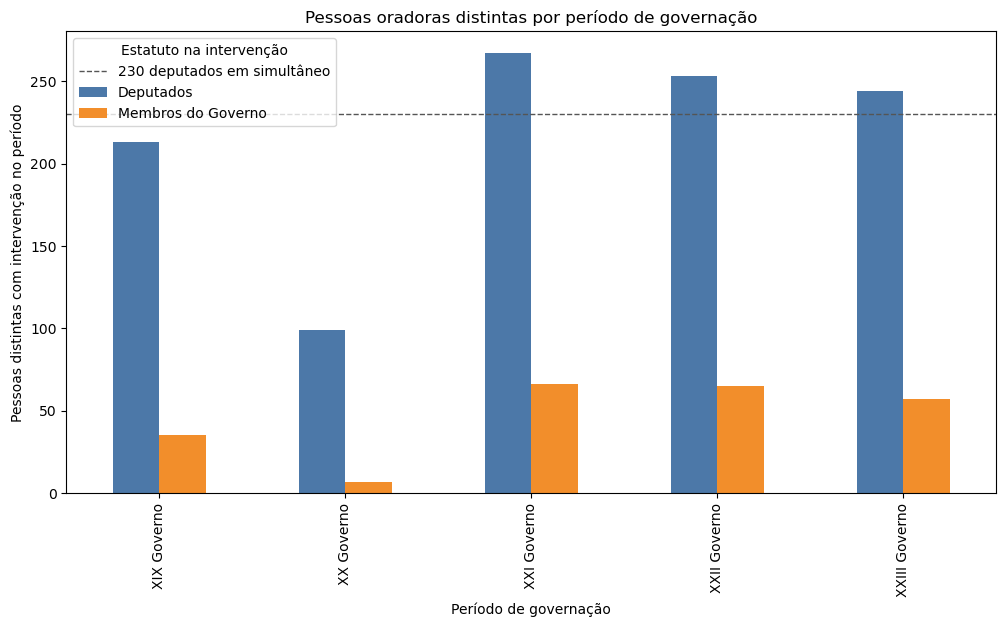

,Deputados,Membros do Governo
período de governação,,
XIX Governo,213,35
XX Governo,99,7
XXI Governo,267,66
XXII Governo,253,65
XXIII Governo,244,57


In [88]:
periodos_governacao_analise = [
    ("XIX Governo", "2015-01-01", "2015-10-30"),
    ("XX Governo", "2015-10-30", "2015-11-26"),
    ("XXI Governo", "2015-11-26", "2019-10-26"),
    ("XXII Governo", "2019-10-26", "2022-03-30"),
    ("XXIII Governo", "2022-03-30", "2024-04-02"),
    ("XXIV Governo", "2024-04-02", None),
]

linhas_governacao = []
for periodo, inicio, fim in periodos_governacao_analise:
    mascara_periodo = intervencoes_validas["Date"].ge(pd.Timestamp(inicio))
    if fim:
        mascara_periodo &= intervencoes_validas["Date"].lt(pd.Timestamp(fim))

    dados_periodo = intervencoes_validas.loc[mascara_periodo]
    if dados_periodo.empty:
        continue

    mascara_governo_periodo = intervencoes_de_membros_governo["Date"].ge(
        pd.Timestamp(inicio)
    )
    if fim:
        mascara_governo_periodo &= intervencoes_de_membros_governo["Date"].lt(
            pd.Timestamp(fim)
        )
    membros_governo_periodo = intervencoes_de_membros_governo.loc[
        mascara_governo_periodo
    ]
    linhas_governacao.append(
        {
            "período de governação": periodo,
            "Deputados": dados_periodo.loc[
                dados_periodo["Speaker_MP"].eq("MP"), "Speaker_ID"
            ].nunique(),
            "Membros do Governo": membros_governo_periodo["Speaker_ID"].nunique(),
        }
    )

oradores_por_estatuto_governacao = pd.DataFrame(linhas_governacao).set_index(
    "período de governação"
)

ax = oradores_por_estatuto_governacao.plot.bar(
    figsize=(12, 6),
    color=["#4C78A8", "#F28E2B"],
)
ax.axhline(230, color="#555555", linestyle="--", linewidth=1, label="230 deputados em simultâneo")
ax.set(
    title="Pessoas oradoras distintas por período de governação",
    xlabel="Período de governação",
    ylabel="Pessoas distintas com intervenção no período",
)
ax.legend(title="Estatuto na intervenção")
plt.show()

oradores_por_estatuto_governacao

Este gráfico apresenta o número de pessoas oradores distintas classificadas como deputadas e como membros do Governo em cada período de governação. 

O número de deputados com intervenções pode ser inferior a 230 porque nem todos os deputados intervêm no período analisado, ou porque as suas intervenções não estão presentes no corpus. Quando o número ultrapassa 230, isso indica que mais de 230 pessoas distintas intervieram ao longo do mesmo período de governação, o que é compatível com substituições, suspensões ou cessação de mandatos. Não significa que existiram mais de 230 deputados em funções ao mesmo tempo. 

### 3.1 Rótulo político e estatuto das pessoas oradoras

A Constituição impede o exercício simultâneo do mandato de deputado e de funções governativas. Por isso, esta análise usa categorias exclusivas e destaca qualquer sobreposição nos dados como caso a verificar.

estatuto_orador,Deputado,Membro do Governo,Outro não deputado
bloco_politico,,,
Governo,21992,12446,574
Oposição,79876,0,2831


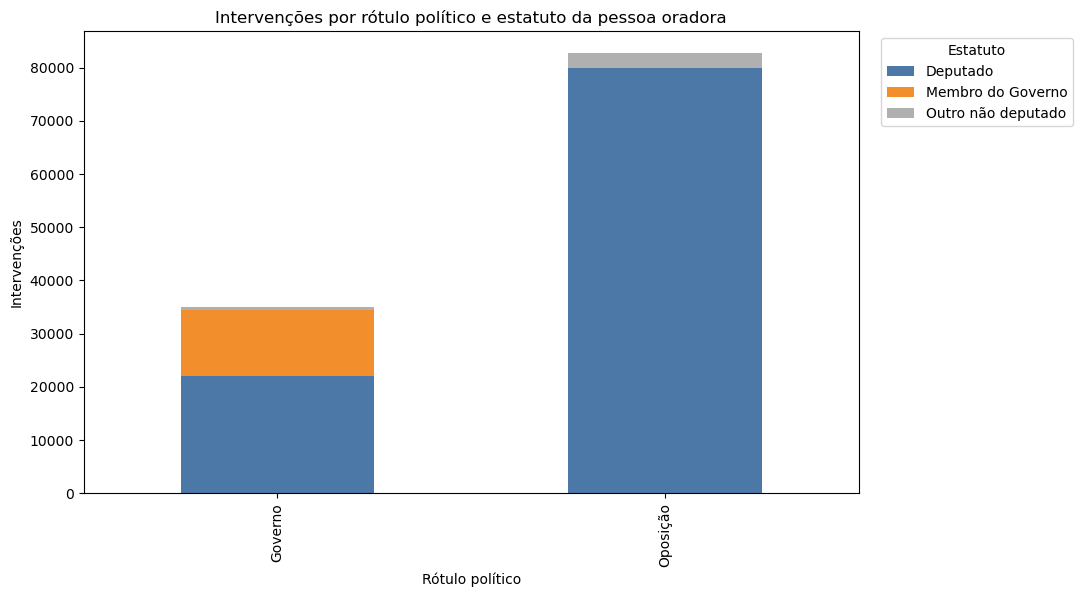

In [89]:
rotulos_politicos = ["Governo", "Oposição"]
estatutos_orador = [
    "Deputado",
    "Membro do Governo",
    "Outro não deputado",
]
cores_estatutos = ["#4C78A8", "#F28E2B", "#B0B0B0"]

intervencoes_rotuladas = intervencoes_validas.loc[
    intervencoes_validas["bloco_politico"].isin(rotulos_politicos)
].copy()
ids_membros_governo = set(intervencoes_de_membros_governo["ID"])
intervencoes_rotuladas["membro_governo"] = intervencoes_rotuladas["ID"].isin(
    ids_membros_governo
)
intervencoes_rotuladas["estatuto_orador"] = "Outro não deputado"
intervencoes_rotuladas.loc[
    intervencoes_rotuladas["Speaker_MP"].eq("MP"), "estatuto_orador"
] = "Deputado"
intervencoes_rotuladas.loc[
    intervencoes_rotuladas["membro_governo"], "estatuto_orador"
] = "Membro do Governo"


resumo_rotulo_estatuto = pd.crosstab(
    intervencoes_rotuladas["bloco_politico"],
    intervencoes_rotuladas["estatuto_orador"],
).reindex(index=rotulos_politicos, columns=estatutos_orador, fill_value=0)
display(resumo_rotulo_estatuto)

ax = resumo_rotulo_estatuto.plot.bar(
    stacked=True,
    figsize=(10, 6),
    color=cores_estatutos,
)
ax.set(
    title="Intervenções por rótulo político e estatuto da pessoa oradora",
    xlabel="Rótulo político",
    ylabel="Intervenções",
)
ax.legend(title="Estatuto", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [90]:
outros_nao_deputados = (
    intervencoes_rotuladas
    .loc[intervencoes_rotuladas["estatuto_orador"].eq("Outro não deputado")]
    .groupby(["Speaker_ID", "Speaker_name"], dropna=False)
    .agg(
        intervencoes=("ID", "size"),
        primeiro_registo=("Date", "min"),
        ultimo_registo=("Date", "max"),
        rotulos_politicos=(
            "bloco_politico",
            lambda serie: ", ".join(sorted(serie.dropna().unique())),
        ),
        papeis_no_corpus=(
            "Speaker_role",
            lambda serie: ", ".join(sorted(serie.dropna().unique())),
        ),
    )
    .reset_index()
    .merge(
        perfil_oradores[[
            "Speaker_ID",
            "teve_mandato_parlamentar_lista",
            "teve_cargo_governo_lista",
        ]],
        on="Speaker_ID",
        how="left",
        validate="one_to_one",
    )
    .sort_values(["intervencoes", "Speaker_name"], ascending=[False, True])
)

print(f"Pessoas identificadas: {len(outros_nao_deputados):,}")
display(outros_nao_deputados)

Pessoas identificadas: 33


,Speaker_ID,Speaker_name,intervencoes,primeiro_registo,ultimo_registo,rotulos_politicos,papeis_no_corpus,teve_mandato_parlamentar_lista,teve_cargo_governo_lista
28,PedroAugustoCunhaPinto,"Augusto Cunha Pinto, Pedro",1091,2022-04-07,2024-02-07,Oposição,Regular,True,False
17,LuísPedroRussodaMotaSoares,"Pedro Russo da Mota Soares, Luís",701,2016-01-20,2019-07-19,Oposição,Regular,False,True
2,AntónioEgrejasLeitãoAmaro,"Egrejas Leitão Amaro, António",535,2015-11-10,2019-07-10,"Governo, Oposição",Regular,True,True
4,BertaMariaCorreiadeAlmeidadeMeloCabral,"Maria Correia de Almeida de Melo Cabral, Berta",154,2015-11-10,2019-07-03,"Governo, Oposição",Regular,False,True
8,FernandoAntónioPortelaRochadeAndrade,"António Portela Rocha de Andrade, Fernando",149,2017-10-13,2019-07-10,Governo,Regular,True,True
3,AntónioFranciscoCostadaSilva,"Francisco Costa da Silva, António",133,2022-04-08,2024-01-04,Oposição,Regular,True,False
20,MariaMargaridaFerreiraMarques,"Margarida Ferreira Marques, Maria",87,2017-09-19,2019-05-29,Governo,Regular,True,True
30,SérgioMonteiro,"Monteiro, Sérgio",79,2015-01-21,2015-07-03,Governo,Regular,False,False
21,MariaTeresadaSilvaMorais,"Teresa da Silva Morais, Maria",77,2015-12-18,2019-06-07,Oposição,Regular,True,True
23,MárciaIsabelDuartePassosResende,"Isabel Duarte Passos Resende, Márcia",76,2022-04-27,2023-03-23,Oposição,Regular,True,False


No corpus analisado, todas as intervenções atribuídas a membros do Governo com afiliação governativa são rotuladas como Governo. 

A categoria "outros não deputados" reúne pessoas que não foram identificadas como deputadas nem como membros do Governo na data da intervenção. Parte destas pessoas teve mandato parlamentar noutro período, mas essa condição não está ativa no ficheiro que lista o percurso dos membros parlamentares (PartaMint-PT-listPerson.xml).

Exemplos Leitão Amaro (2015-2019) foi Vice-Presidente do Grupo Parlamentar do PSD, sendo portanto deputado. No entanto ele não aparece no dataset como deputado. 

## 4. Composição política

### 4.1 Intervenções e extensão média por afiliação partidária

A análise usa a afiliação registada em `Speaker_party`. Entradas sem afiliação são excluídas, mas independentes e não inscritos mantêm-se como categorias próprias quando registados.

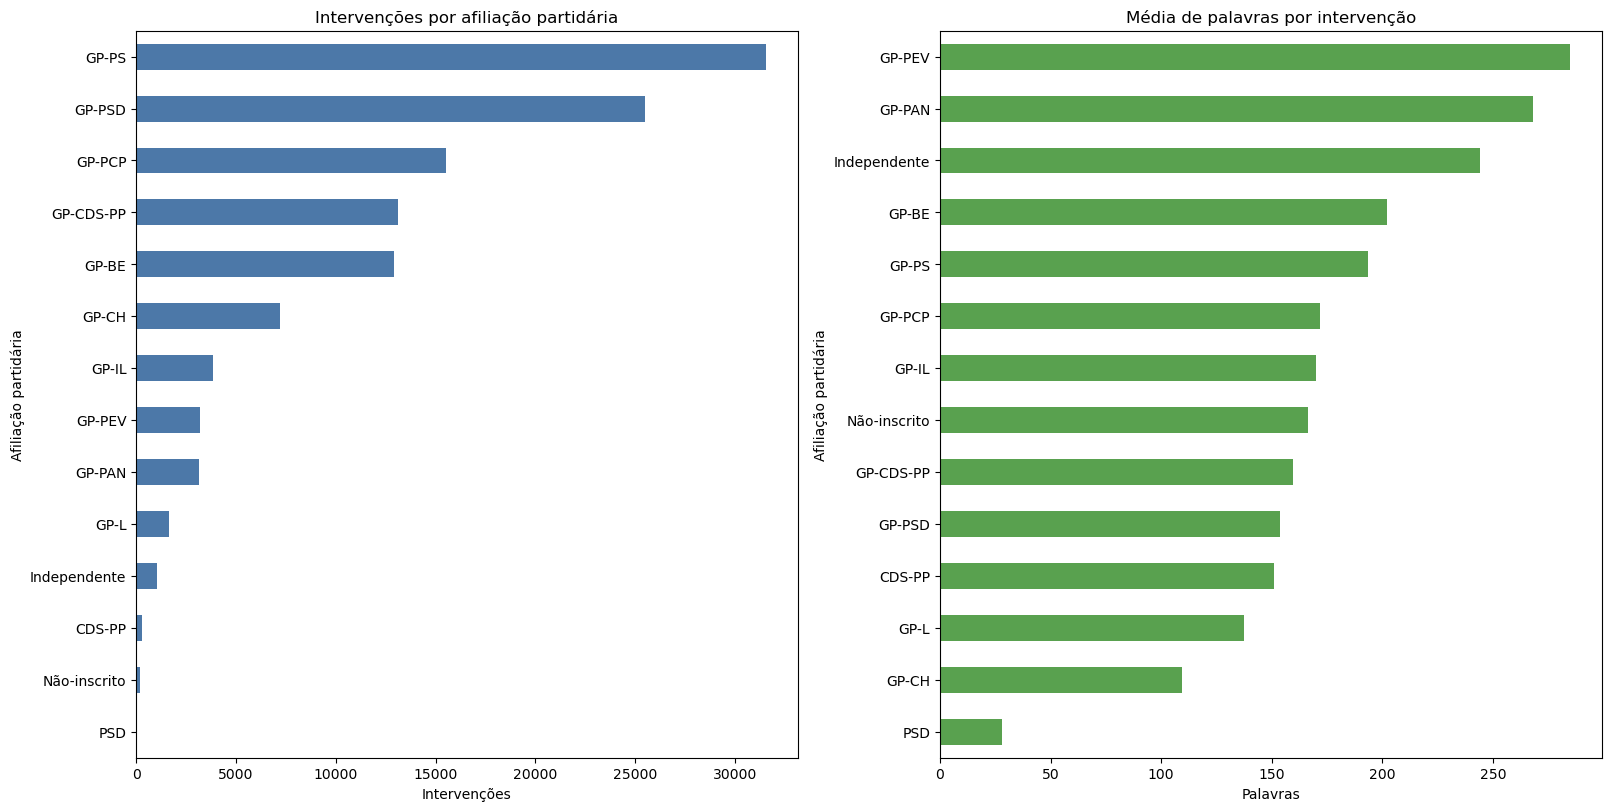

,intervencoes,media_palavras
Speaker_party,,
GP-PS,31564,193.307597
GP-PSD,25484,153.779352
GP-PCP,15503,171.609301
GP-CDS-PP,13121,159.629297
GP-BE,12900,202.229070
GP-CH,7201,109.464658
GP-IL,3846,170.029121
GP-PEV,3189,284.879900
GP-PAN,3165,268.042654


In [91]:
intervencoes_com_partido = intervencoes_validas.loc[
    intervencoes_validas["Speaker_party"].notna()
    & intervencoes_validas["Speaker_party"].ne("")
].copy()

resumo_partidos = (
    intervencoes_com_partido
    .groupby("Speaker_party")
    .agg(
        intervencoes=("ID", "size"),
        media_palavras=("n_palavras", "mean"),
    )
    .sort_values("intervencoes", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)

resumo_partidos["intervencoes"].sort_values().plot.barh(
    ax=axes[0], color="#4C78A8"
)
axes[0].set(
    title="Intervenções por afiliação partidária",
    xlabel="Intervenções",
    ylabel="Afiliação partidária",
)

resumo_partidos["media_palavras"].sort_values().plot.barh(
    ax=axes[1], color="#59A14F"
)
axes[1].set(
    title="Média de palavras por intervenção",
    xlabel="Palavras",
    ylabel="Afiliação partidária",
)

plt.show()
resumo_partidos

O corpus é fortemente concentrado em volume de intervenções nos grupos parlamentes PS e PSD, seguidos por PCP, CDS-PP e BE. Esta assimetria implica que tópicos globais serão mais influenciados pelos partidos com maior produção textual. 

O número de intervenções e a extensão média não seguem o mesmo padrão. PEV, PAN e independentes apresentam intervenções mais longas, mas têm poucos casos; por isso, as suas médias são mais sensíveis a intervenções excecionalmente extensas. Em contraste, PS e PSD combinam grande volume com extensões médias intermédias, oferecendo cobertura mais robusta para modelação. 

Assim, a análise temática por partido deve considerar simultanemente volume e comprimento dos textos. Partidos com baixo número de intervenções devem ser interpretados com cautela ou sujeitos a um limiar mínimo de documentos/palavras por janela temporal. 

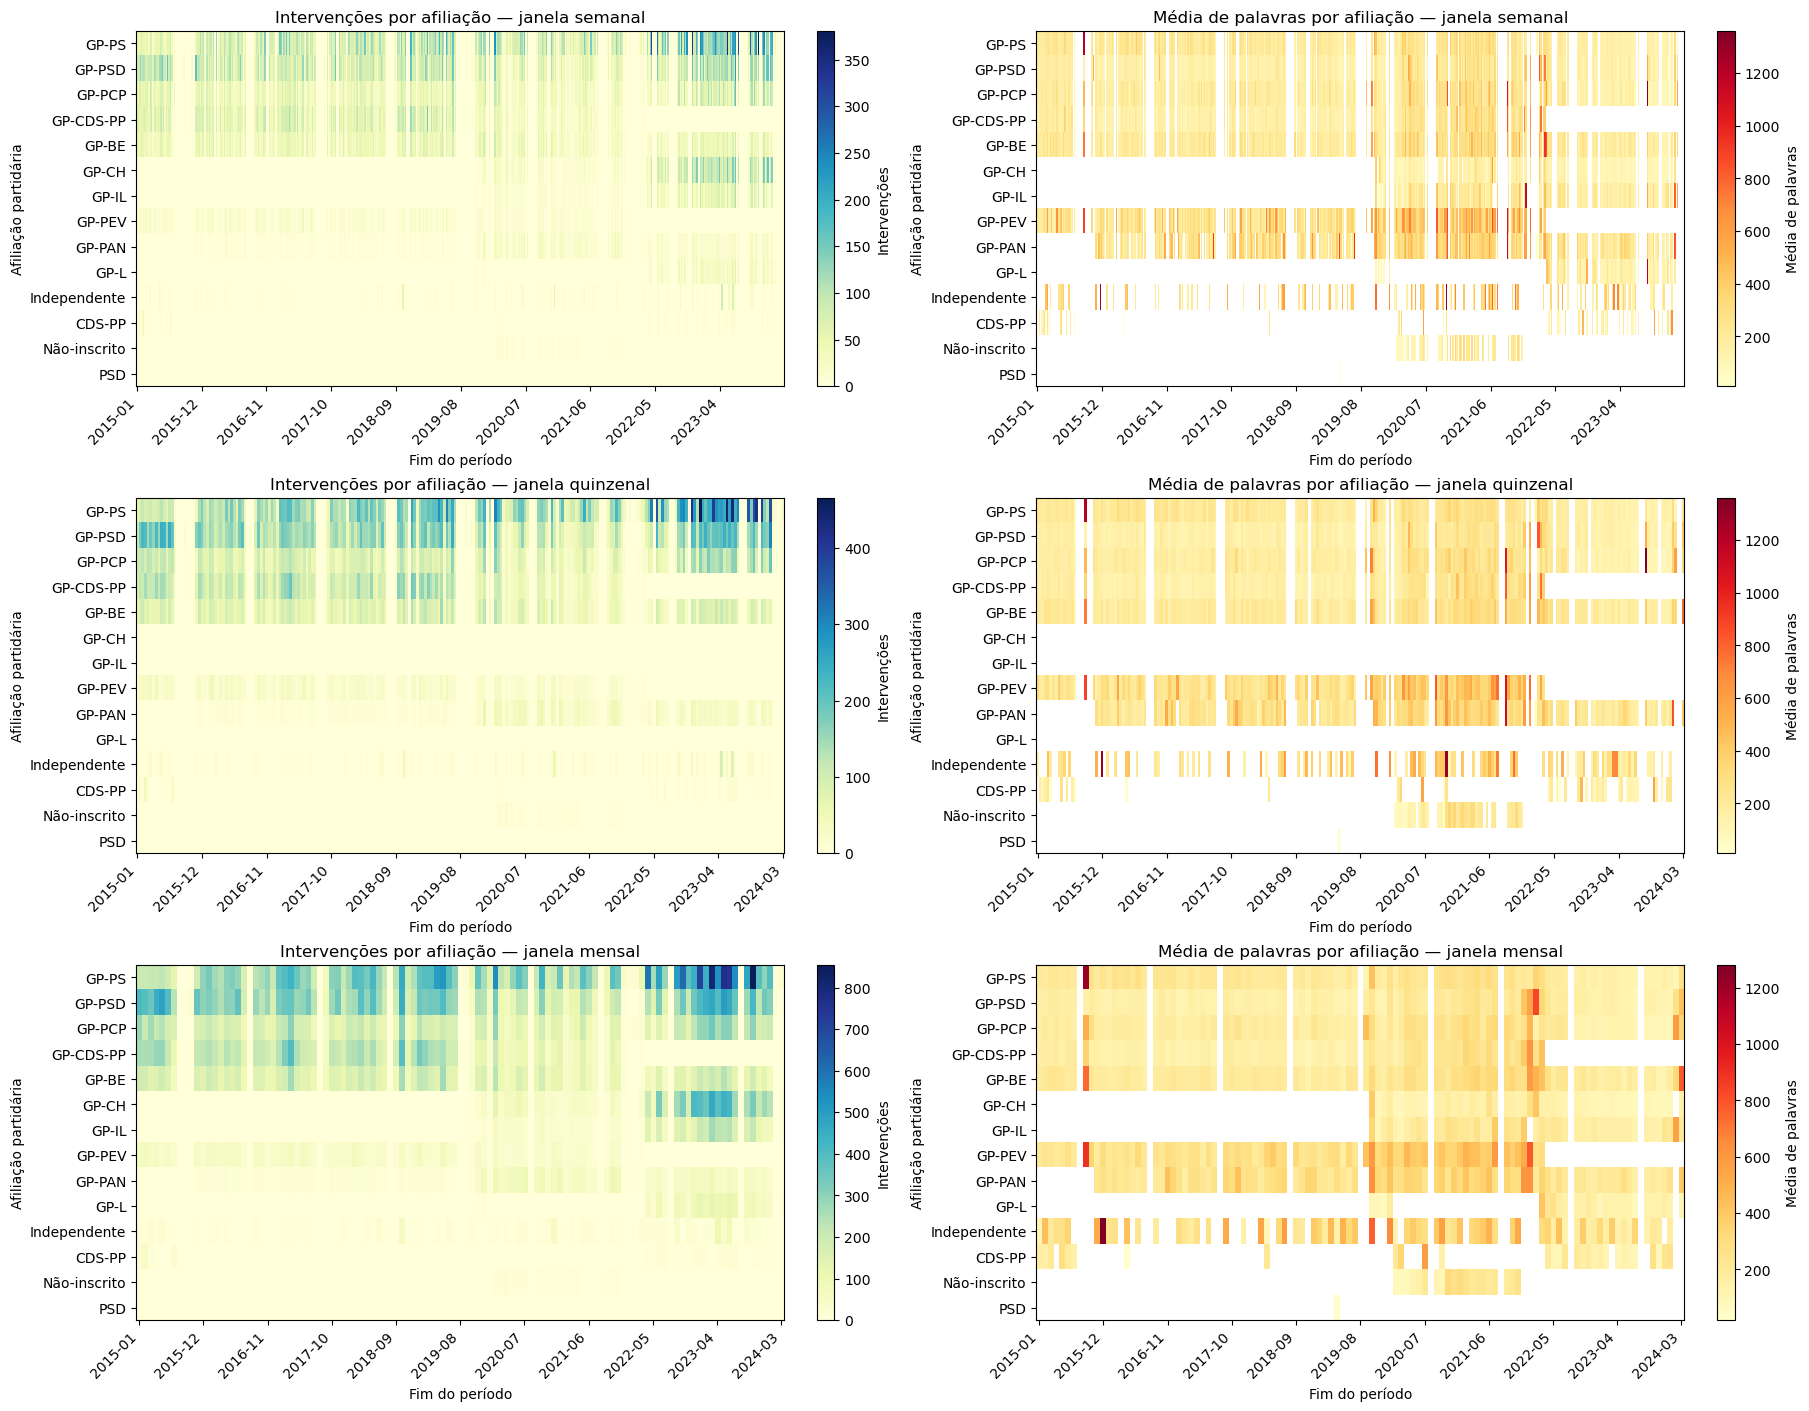

In [92]:
janelas_partidos = {
    "Semanal": "W-SUN",
    "Quinzenal": "2W-SUN",
    "Mensal": "M",
}
partidos = resumo_partidos.index.tolist()
resumos_partidos_janelas = {}

for nome, frequencia in janelas_partidos.items():
    periodos = intervencoes_validas.set_index("Date").resample(frequencia).size().index
    contagens = (
        intervencoes_com_partido.set_index("Date")
        .groupby("Speaker_party")
        .resample(frequencia)
        .size()
        .unstack("Speaker_party")
        .reindex(index=periodos, columns=partidos, fill_value=0)
        .fillna(0)
    )
    medias = (
        intervencoes_com_partido.set_index("Date")
        .groupby("Speaker_party")
        .resample(frequencia)["n_palavras"]
        .mean()
        .unstack("Speaker_party")
        .reindex(index=periodos, columns=partidos)
    )
    resumos_partidos_janelas[nome] = {
        "contagens": contagens,
        "medias": medias,
    }

fig, axes = plt.subplots(3, 2, figsize=(18, 14), constrained_layout=True)

for linha, (nome, resumo) in enumerate(resumos_partidos_janelas.items()):
    for coluna, (metrica, titulo, escala) in enumerate([
        ("contagens", "Intervenções", "YlGnBu"),
        ("medias", "Média de palavras", "YlOrRd"),
    ]):
        matriz = resumo[metrica].T
        imagem = axes[linha, coluna].imshow(
            matriz, aspect="auto", interpolation="nearest", cmap=escala
        )
        passo = max(1, len(matriz.columns) // 10)
        posicoes = list(range(0, len(matriz.columns), passo))
        axes[linha, coluna].set(
            title=f"{titulo} por afiliação — janela {nome.lower()}",
            xlabel="Fim do período",
            ylabel="Afiliação partidária",
        )
        axes[linha, coluna].set_yticks(range(len(matriz.index)), matriz.index)
        axes[linha, coluna].set_xticks(
            posicoes,
            [matriz.columns[posicao].strftime("%Y-%m") for posicao in posicoes],
            rotation=45,
            ha="right",
        )
        fig.colorbar(imagem, ax=axes[linha, coluna], label=titulo)

plt.show()

- PS e PSD mantêm cobertura elevada ao longo de todo o corpus; PCP, CDS-PP e BE têm cobertura relevante, mas menor. 

- CH, IL e Livre surgem apenas nas fases mais recentes, coerentemente com a sua entrada/representação parlamentar nesses períodos. 

- A escala semanal é demasiado fragmentada para partidos pequenos: há muitos períodos vazios e médias de palavras instáveis.

- A escala quinzenal melhora a continuidade, mas ainda mantém lacunas relevantes.

- A escala mensal oferece a leitura mais estável da atividade partidária, preservando mudanças temporais sem gerar tantas células vazias. 

- Picos muito altos na média de palavras, sobretudo em partidos com pouca atividade e em independentes, devem ser interpretados com cautela: podem resultar de poucas intervenções muito longas, não de uma mudança sistemática no discurso. 

,período de governação,afiliação partidária,Governo,Oposição,proporção Governo
0,XIX Governo,CDS-PP,119,0,1.0
1,XIX Governo,GP-BE,0,1072,0.0
2,XIX Governo,GP-CDS-PP,1660,0,1.0
3,XIX Governo,GP-PCP,0,1545,0.0
4,XIX Governo,GP-PEV,0,370,0.0
5,XIX Governo,GP-PS,0,1380,0.0
6,XIX Governo,GP-PSD,2728,0,1.0
7,XX Governo,GP-BE,0,117,0.0
8,XX Governo,GP-CDS-PP,170,0,1.0
9,XX Governo,GP-PAN,0,13,0.0


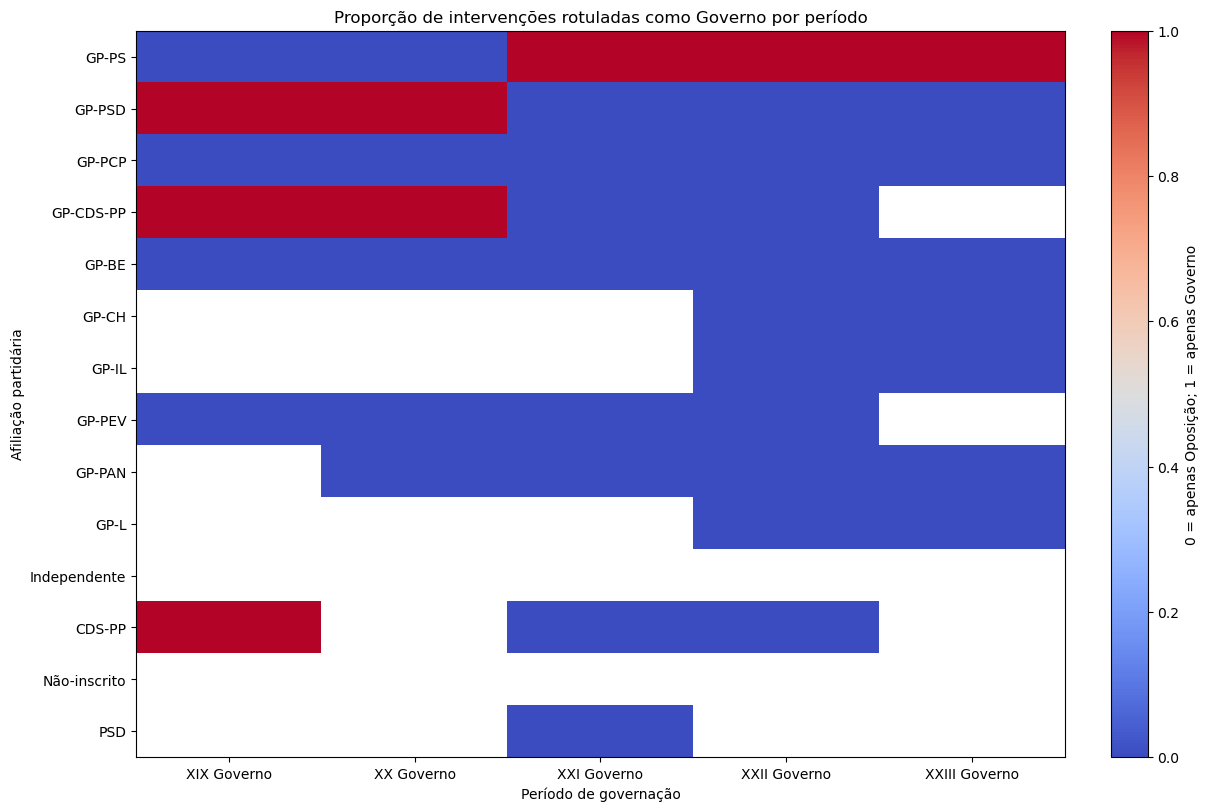

In [93]:
linhas_partido_rotulo = []

for periodo, inicio, fim in periodos_governacao_analise:
    mascara = intervencoes_com_partido["Date"].ge(pd.Timestamp(inicio))
    if fim:
        mascara &= intervencoes_com_partido["Date"].lt(pd.Timestamp(fim))

    resumo_periodo = (
        intervencoes_com_partido.loc[mascara]
        .loc[lambda dados: dados["bloco_politico"].isin(rotulos_politicos)]
        .groupby(["Speaker_party", "bloco_politico"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=rotulos_politicos, fill_value=0)
    )

    for partido, valores in resumo_periodo.iterrows():
        total = valores.sum()
        linhas_partido_rotulo.append(
            {
                "período de governação": periodo,
                "afiliação partidária": partido,
                "Governo": valores["Governo"],
                "Oposição": valores["Oposição"],
                "proporção Governo": valores["Governo"] / total,
            }
        )

resumo_partido_rotulo_governacao = pd.DataFrame(linhas_partido_rotulo)
display(resumo_partido_rotulo_governacao)

matriz_rotulo_governo = resumo_partido_rotulo_governacao.pivot(
    index="afiliação partidária",
    columns="período de governação",
    values="proporção Governo",
).reindex(index=partidos)

fig, eixo = plt.subplots(figsize=(12, 8), constrained_layout=True)
imagem = eixo.imshow(
    matriz_rotulo_governo,
    aspect="auto",
    interpolation="nearest",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
)
eixo.set(
    title="Proporção de intervenções rotuladas como Governo por período",
    xlabel="Período de governação",
    ylabel="Afiliação partidária",
)
eixo.set_xticks(range(len(matriz_rotulo_governo.columns)), matriz_rotulo_governo.columns)
eixo.set_yticks(range(len(matriz_rotulo_governo.index)), matriz_rotulo_governo.index)
fig.colorbar(
    imagem,
    ax=eixo,
    label="0 = apenas Oposição; 1 = apenas Governo",
)
plt.show()

A label Governo/Oposição representa participação formal no executivo, não apoio parlamentar.

## 5. Atividade temporal e diagnóstico complementar

Esta secção descreve a cadência temporal do corpus. A comparação por semana, quinzena e mês é um diagnóstico complementar para experiências futuras, não uma decisão automática sobre a janela do BERTilda. As semanas e quinzenas terminam ao domingo; os meses correspondem a meses de calendário.

In [94]:
janelas_temporais = {
    "Semanal": "W-SUN",
    "Quinzenal": "2W-SUN",
    "Mensal": "M",
}

resumos_janelas = {
    nome: (
        intervencoes_validas.set_index("Date").resample(frequencia)
        .agg(
            intervencoes=("ID", "size"),
            palavras=("n_palavras", "sum"),
            media_palavras=("n_palavras", "mean"),
            mediana_palavras = ("n_palavras","median")
        )
        .rename_axis("fim_periodo")
    )
    for nome, frequencia in janelas_temporais.items()
}

# Períodos definidos pelas datas de tomada de posse dos governos constitucionais.
periodos_governacao = [
    ("2015-01-01", "2015-10-30", "XIX Governo", "#D9EAF7"),
    ("2015-10-30", "2015-11-26", "XX Governo", "#FCE5CD"),
    ("2015-11-26", "2019-10-26", "XXI Governo", "#D9EAD3"),
    ("2019-10-26", "2022-03-30", "XXII Governo", "#FFF2CC"),
    ("2022-03-30", "2024-04-02", "XXIII Governo", "#D9D2E9"),
    ("2024-04-02", None, "XXIV Governo", "#F4CCCC"),
]

legenda_governacao = [
    Patch(facecolor=cor, alpha=0.35, label=nome)
    for _, _, nome, cor in periodos_governacao
]

def marcar_periodos_governacao(eixo):
    fim_corpus = intervencoes_validas["Date"].max() + pd.Timedelta(days=1)
    for inicio, fim, _, cor in periodos_governacao:
        eixo.axvspan(
            pd.Timestamp(inicio),
            pd.Timestamp(fim) if fim else fim_corpus,
            color=cor,
            alpha=0.35,
            zorder=0,
        )

transicoes_governacao_anual = [
    (2015, "XIX → XX → XXI"),
    (2019, "XXI → XXII"),
    (2022, "XXII → XXIII"),
    (2024, "XXIII → XXIV"),
]

def marcar_transicoes_governacao_anual(eixo):
    anos = list(resumo_anual.index.astype(int))
    for ano, rotulo in transicoes_governacao_anual:
        if ano in anos:
            posicao = anos.index(ano)
            eixo.axvline(posicao, color="#555555", linestyle="--", linewidth=1)
            eixo.annotate(
                rotulo,
                xy=(posicao, 1),
                xycoords=("data", "axes fraction"),
                xytext=(3, -4),
                textcoords="offset points",
                rotation=90,
                va="top",
                fontsize=7,
                color="#555555",
            )

for nome, resumo in resumos_janelas.items():
    print(f"\n{nome}")
    display(resumo)


Semanal


,intervencoes,palavras,media_palavras,mediana_palavras
fim_periodo,,,,
2015-01-11,444,74182,167.076577,97.5
2015-01-18,278,53637,192.938849,115.5
2015-01-25,350,53954,154.154286,92.5
2015-02-01,374,64903,173.537433,110.5
2015-02-08,342,58944,172.350877,94.0
...,...,...,...,...
2024-02-18,0,0,NaN,NaN
2024-02-25,0,0,NaN,NaN
2024-03-03,0,0,NaN,NaN



Quinzenal


,intervencoes,palavras,media_palavras,mediana_palavras
fim_periodo,,,,
2015-01-11,444,74182,167.076577,97.5
2015-01-25,628,107591,171.323248,98.0
2015-02-08,716,123847,172.970670,103.0
2015-02-22,699,124010,177.410587,109.0
2015-03-08,621,137553,221.502415,125.0
...,...,...,...,...
2024-01-28,62,20777,335.112903,240.5
2024-02-11,28,6744,240.857143,87.0
2024-02-25,0,0,NaN,NaN



Mensal


,intervencoes,palavras,media_palavras,mediana_palavras
fim_periodo,,,,
2015-01-31,1446,246676,170.591978,102.0
2015-02-28,1371,250420,182.654996,105.0
2015-03-31,1336,252157,188.740269,98.0
2015-04-30,1389,279437,201.178546,114.0
2015-05-31,1499,262317,174.994663,91.0
...,...,...,...,...
2023-11-30,1330,151000,113.533835,71.0
2023-12-31,1500,188242,125.494667,61.0
2024-01-31,1399,179956,128.631880,66.0


A escala semanal apresenta maior variabilidade no número de intervenções e palavras observadas. Os períodos sem atividade correspondem a recessos ou interrupções da atividade parlamentar, não a documentos vazios. 

A escala quinzenal agrega mais atividade por período, mas continua a expor diferenças relevantes entre partidos e subgrupos. 

A escala mensal concentra mais intervenções e palavras e suaviza variações de curto prazo. Esta é uma observação descritiva, não uma seleção da janela de modelação. 

Conclusão: escalas temporais diferentes descrevem níveis diferentes de atividade parlamentar. A sua comparação serve para contextualizar o corpus e identificar períodos atípicos; a escolha de uma configuração de modelação exige posteriormente um piloto próprio.

### 5.1 Comparação visual da atividade temporal

Cada linha mostra uma granularidade temporal, permitindo identificar períodos de baixa cobertura e avaliar se uma janela mais longa reduz a variabilidade excessiva.

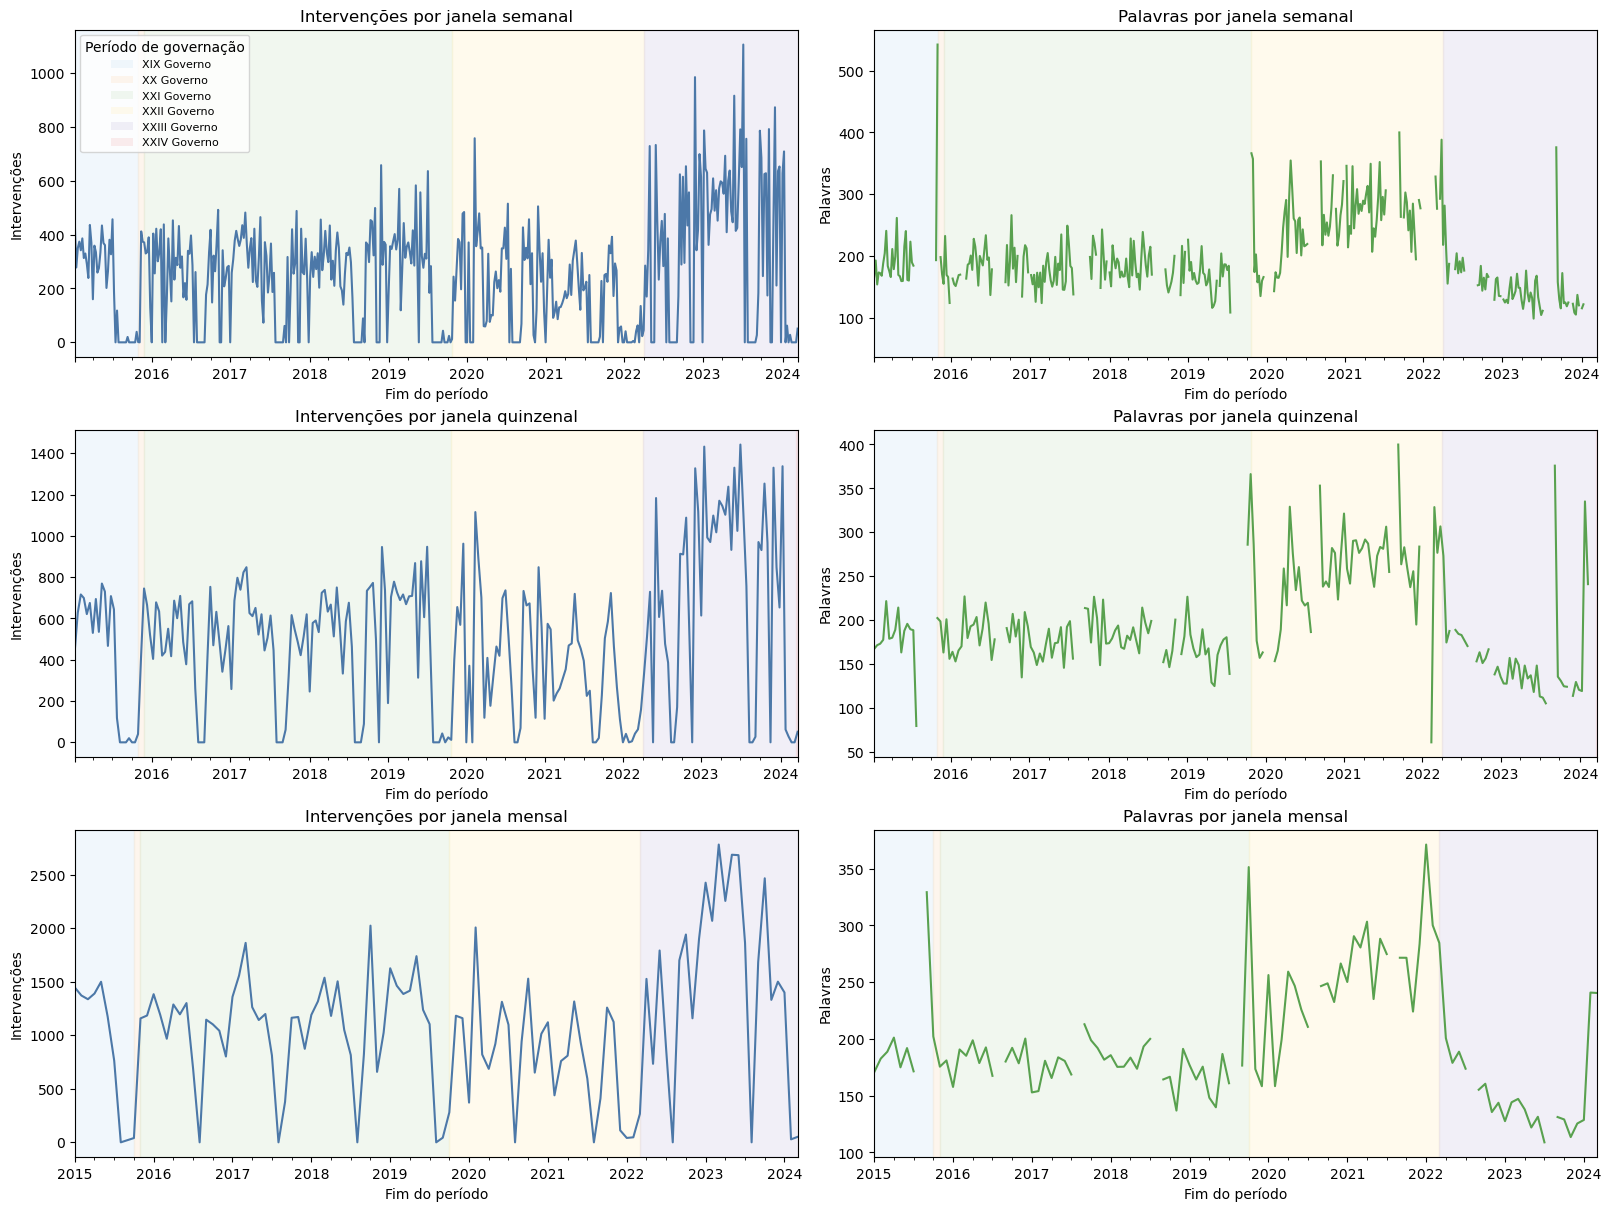

In [95]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12), constrained_layout=True)

for linha, (nome, resumo) in enumerate(resumos_janelas.items()):
    resumo["intervencoes"].plot(ax=axes[linha, 0], color="#4C78A8")
    axes[linha, 0].set(
        title=f"Intervenções por janela {nome.lower()}",
        xlabel="Fim do período",
        ylabel="Intervenções",
    )

    resumo["media_palavras"].plot(ax=axes[linha, 1], color="#59A14F")
    axes[linha, 1].set(
        title=f"Palavras por janela {nome.lower()}",
        xlabel="Fim do período",
        ylabel="Palavras",
    )
    marcar_periodos_governacao(axes[linha, 0])
    marcar_periodos_governacao(axes[linha, 1])

axes[0, 0].legend(
    handles=legenda_governacao,
    title="Período de governação",
    loc="upper left",
    fontsize=8,
)

plt.show()

### 5.2 Comparabilidade das janelas candidatas

Uma janela temporal é comparável quando combina atividade observada, diversidade de intervenientes e composição política suficientes. Nesta secção, os períodos são agregados apenas quando existem intervenções; não se interpretam recessos parlamentares como documentos ou janelas vazias.

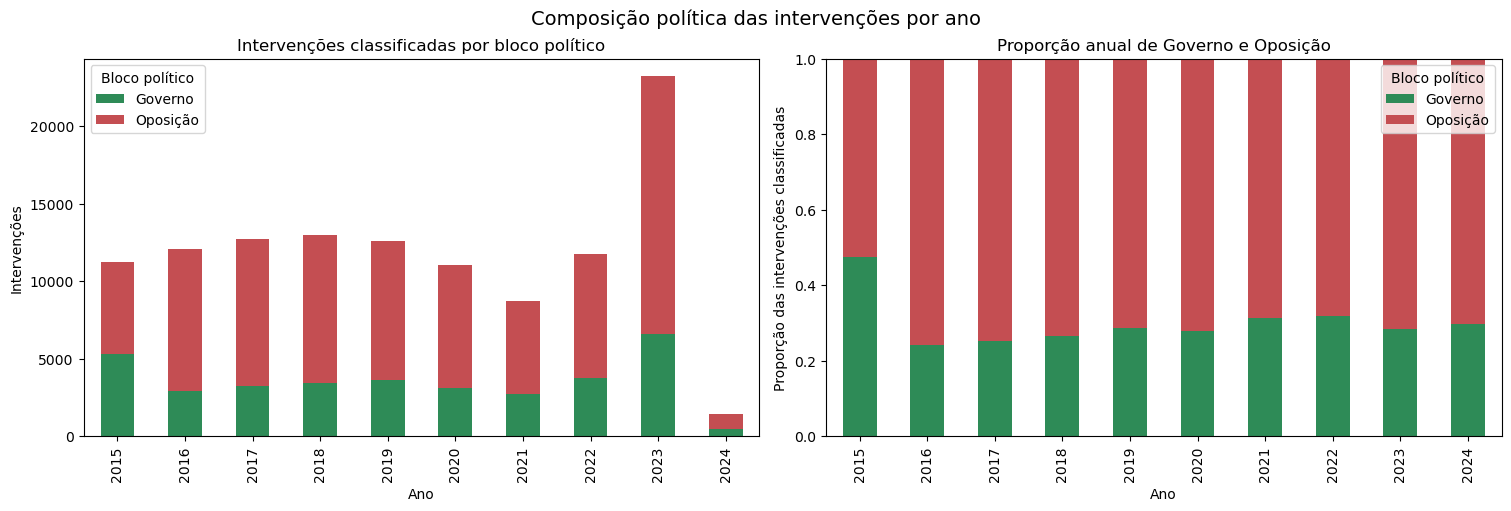

,intervencoes,palavras,media_palavras,oradores,Governo,Oposição,intervencoes_classificadas,proporcao_governo,proporcao_oposicao
ano,,,,,,,,,
2015,11379,2079383,182.738641,331,5313,5896,11209,0.473994,0.526006
2016,12104,2224324,183.767680,269,2904,9155,12059,0.240816,0.759184
2017,12775,2251294,176.226536,273,3227,9515,12742,0.253257,0.746743
2018,13119,2323668,177.122342,284,3441,9558,12999,0.264713,0.735287
2019,12630,2126863,168.397704,346,3597,8977,12574,0.286066,0.713934
2020,11345,2542386,224.097488,278,3086,7975,11061,0.278998,0.721002
2021,8872,2343719,264.170311,282,2719,5978,8697,0.312637,0.687363
2022,11964,2035788,170.159478,291,3726,8000,11726,0.317755,0.682245
2023,23731,3088050,130.127260,280,6564,16628,23192,0.283029,0.716971


In [96]:
blocos_esperados = ["Governo", "Oposição"]

contagens_blocos = (
    intervencoes_validas
    .loc[intervencoes_validas["bloco_politico"].isin(blocos_esperados)]
    .groupby(["ano", "bloco_politico"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=blocos_esperados, fill_value=0)
)

resumo_anual = resumo_anual.join(contagens_blocos, how="left").fillna(0)
resumo_anual["intervencoes_classificadas"] = (
    resumo_anual["Governo"] + resumo_anual["Oposição"]
)
resumo_anual["proporcao_governo"] = (
    resumo_anual["Governo"] / resumo_anual["intervencoes_classificadas"]
).where(resumo_anual["intervencoes_classificadas"].gt(0))
resumo_anual["proporcao_oposicao"] = (
    resumo_anual["Oposição"] / resumo_anual["intervencoes_classificadas"]
).where(resumo_anual["intervencoes_classificadas"].gt(0))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

resumo_anual[["Governo", "Oposição"]].plot(
    kind="bar", stacked=True, ax=axes[0], color=["#2E8B57", "#C44E52"]
)
axes[0].set(
    title="Intervenções classificadas por bloco político",
    xlabel="Ano", ylabel="Intervenções"
)
axes[0].legend(title="Bloco político")

resumo_anual[["proporcao_governo", "proporcao_oposicao"]].plot(
    kind="bar", stacked=True, ax=axes[1], color=["#2E8B57", "#C44E52"]
)
axes[1].set(
    title="Proporção anual de Governo e Oposição",
    xlabel="Ano", ylabel="Proporção das intervenções classificadas", ylim=(0, 1)
)
axes[1].legend(["Governo", "Oposição"], title="Bloco político")

fig.suptitle("Composição política das intervenções por ano", fontsize=14)
plt.show()

resumo_anual

### 5.3 Composição Governo e Oposição por janela

Os gráficos da esquerda apresentam o volume de intervenções classificadas por bloco. Os gráficos da direita apresentam a respetiva proporção; períodos sem intervenções classificadas permanecem sem proporção para evitar interpretar ausência de dados como equilíbrio político.

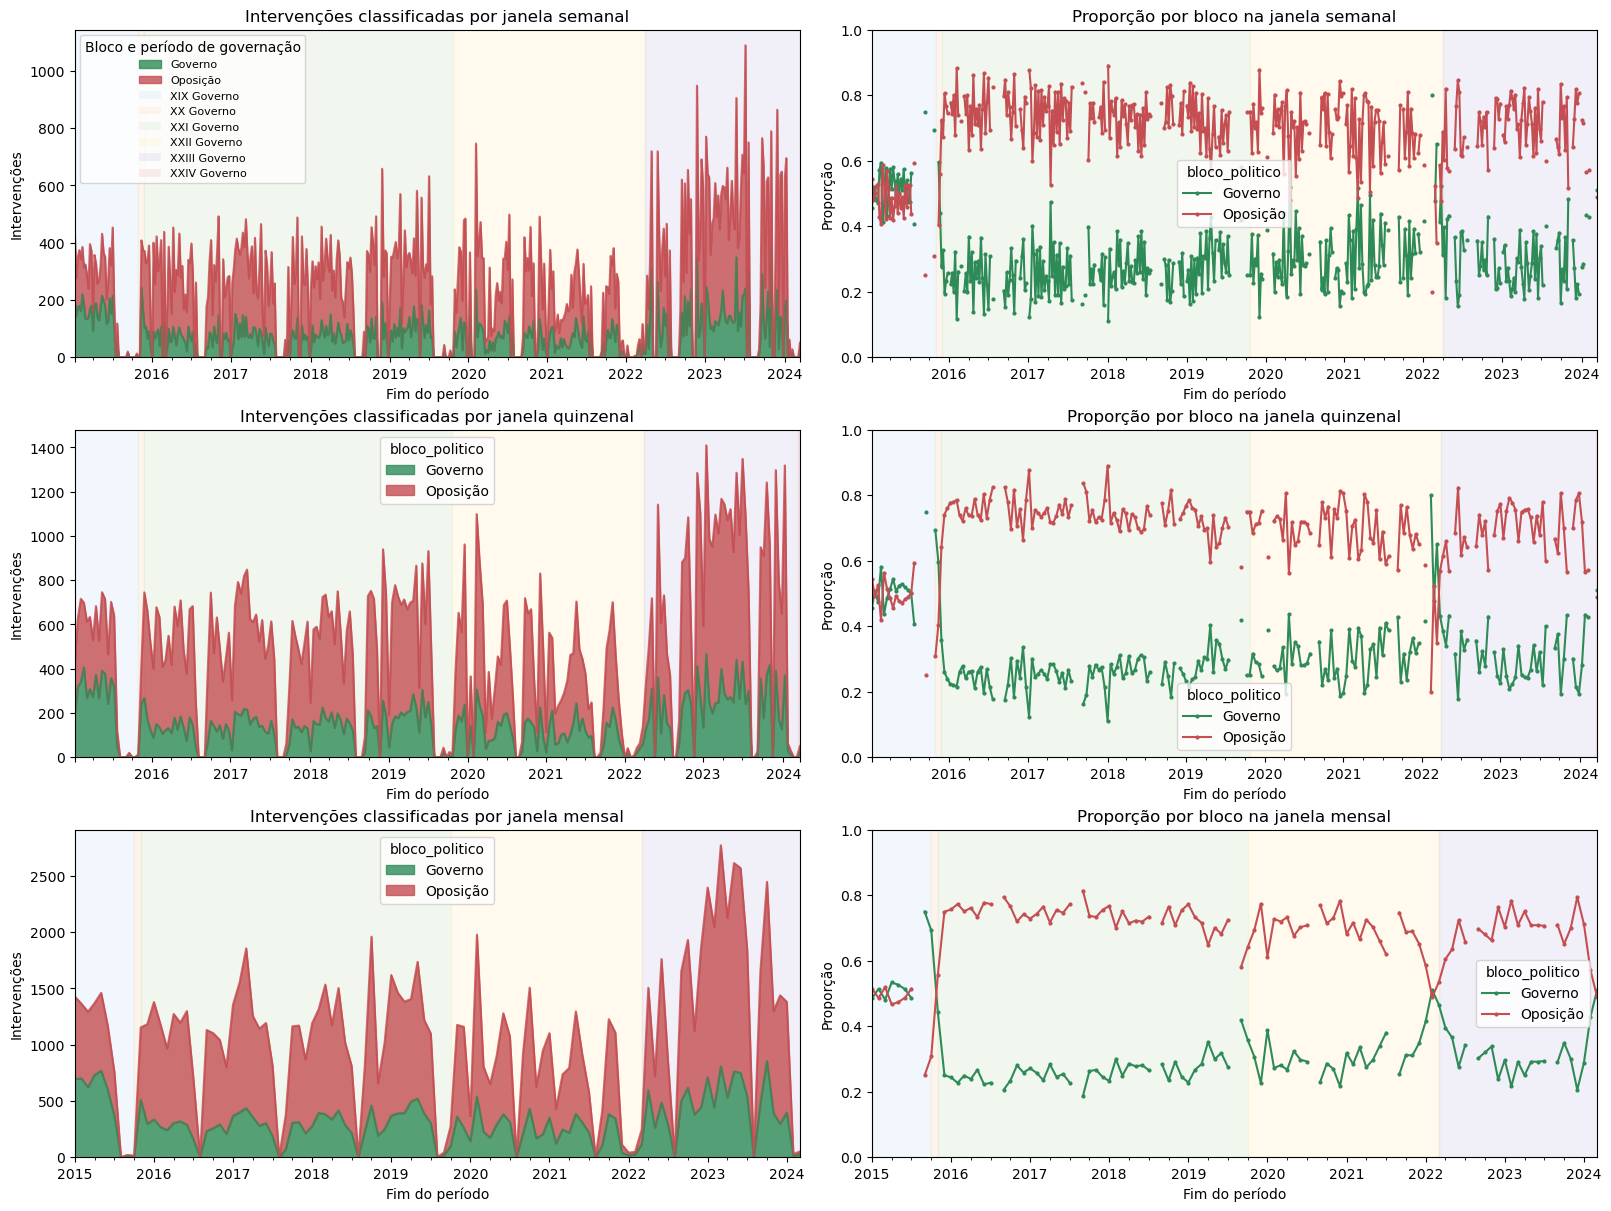

In [97]:
intervencoes_classificadas = intervencoes_validas.loc[
    intervencoes_validas["bloco_politico"].isin(blocos_esperados)
].copy()

cobertura_blocos_janelas = {}

for nome, frequencia in janelas_temporais.items():
    contagens = (
        intervencoes_classificadas.set_index("Date")
        .groupby("bloco_politico")
        .resample(frequencia)
        .size()
        .unstack("bloco_politico")
        .reindex(
            index=resumos_janelas[nome].index,
            columns=blocos_esperados,
            fill_value=0,
        )
    )

    total_classificado = contagens.sum(axis=1)
    proporcoes = contagens.div(total_classificado.where(total_classificado.gt(0)), axis=0)
    cobertura_blocos_janelas[nome] = {
        "contagens": contagens,
        "proporcoes": proporcoes,
    }

fig, axes = plt.subplots(3, 2, figsize=(16, 12), constrained_layout=True)

for linha, (nome, cobertura) in enumerate(cobertura_blocos_janelas.items()):
    cobertura["contagens"].plot.area(
        ax=axes[linha, 0],
        stacked=True,
        color=["#2E8B57", "#C44E52"],
        alpha=0.8,
    )
    axes[linha, 0].set(
        title=f"Intervenções classificadas por janela {nome.lower()}",
        xlabel="Fim do período",
        ylabel="Intervenções",
    )

    cobertura["proporcoes"].plot(
        ax=axes[linha, 1],
        color=["#2E8B57", "#C44E52"],
        marker="o",
        markersize=2,
    )
    axes[linha, 1].set(
        title=f"Proporção por bloco na janela {nome.lower()}",
        xlabel="Fim do período",
        ylabel="Proporção",
        ylim=(0, 1),
    )
    marcar_periodos_governacao(axes[linha, 0])
    marcar_periodos_governacao(axes[linha, 1])

handles, etiquetas = axes[0, 0].get_legend_handles_labels()
axes[0, 0].legend(
    handles + legenda_governacao,
    etiquetas + [periodo[2] for periodo in periodos_governacao],
    title="Bloco e período de governação",
    loc="upper left",
    fontsize=8,
)

plt.show()

## 6. Sazonalidade da atividade parlamentar

Esta análise agrega todos os anos do corpus por mês do calendário. Mostra o volume total de intervenções e o número de dias distintos com atividade parlamentar, permitindo identificar períodos de maior e menor ritmo parlamentar sem assumir que a sazonalidade determina a escolha de janelas temporais.

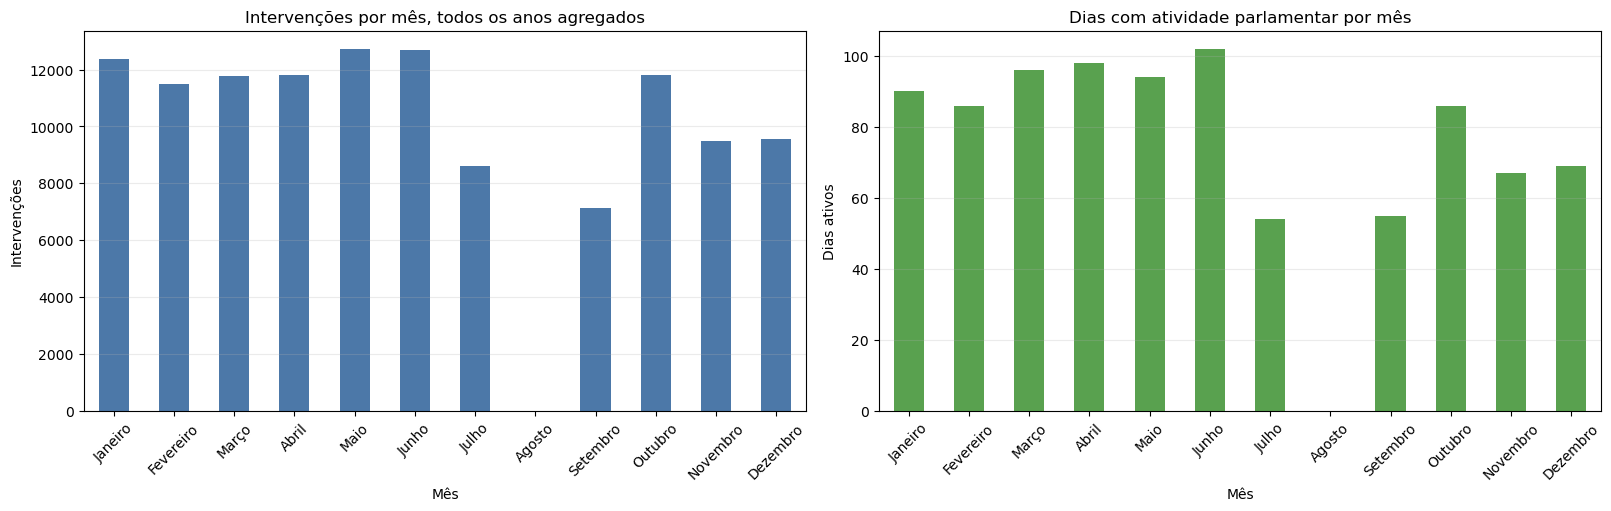

,intervencoes,dias_ativos
mes,,
Janeiro,12358,90
Fevereiro,11485,86
Março,11763,96
Abril,11809,98
Maio,12729,94
Junho,12673,102
Julho,8601,54
Agosto,0,0
Setembro,7142,55


In [98]:
nomes_meses = {
    1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril",
    5: "Maio", 6: "Junho", 7: "Julho", 8: "Agosto",
    9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro",
}

dados_sazonalidade = intervencoes_validas.copy()
dados_sazonalidade["mes"] = dados_sazonalidade["Date"].dt.month

sazonalidade_mensal = (
    dados_sazonalidade
    .groupby("mes")
    .agg(
        intervencoes=("ID", "size"),
        dias_ativos=("Date", lambda datas: datas.dt.normalize().nunique()),
    )
    .reindex(range(1, 13), fill_value=0)
    .rename(index=nomes_meses)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
sazonalidade_mensal["intervencoes"].plot.bar(ax=axes[0], color="#4C78A8")
axes[0].set(
    title="Intervenções por mês, todos os anos agregados",
    xlabel="Mês",
    ylabel="Intervenções",
)

sazonalidade_mensal["dias_ativos"].plot.bar(ax=axes[1], color="#59A14F")
axes[1].set(
    title="Dias com atividade parlamentar por mês",
    xlabel="Mês",
    ylabel="Dias ativos",
)

for eixo in axes:
    eixo.tick_params(axis="x", rotation=45)
    eixo.grid(axis="y", alpha=0.25)

plt.show()
sazonalidade_mensal


## 7. Conclusões EDA

A visualização anual integra volume, extensão, intervenientes e composição política no contexto de longo prazo. O diagnóstico por janelas permanece abaixo como informação complementar.

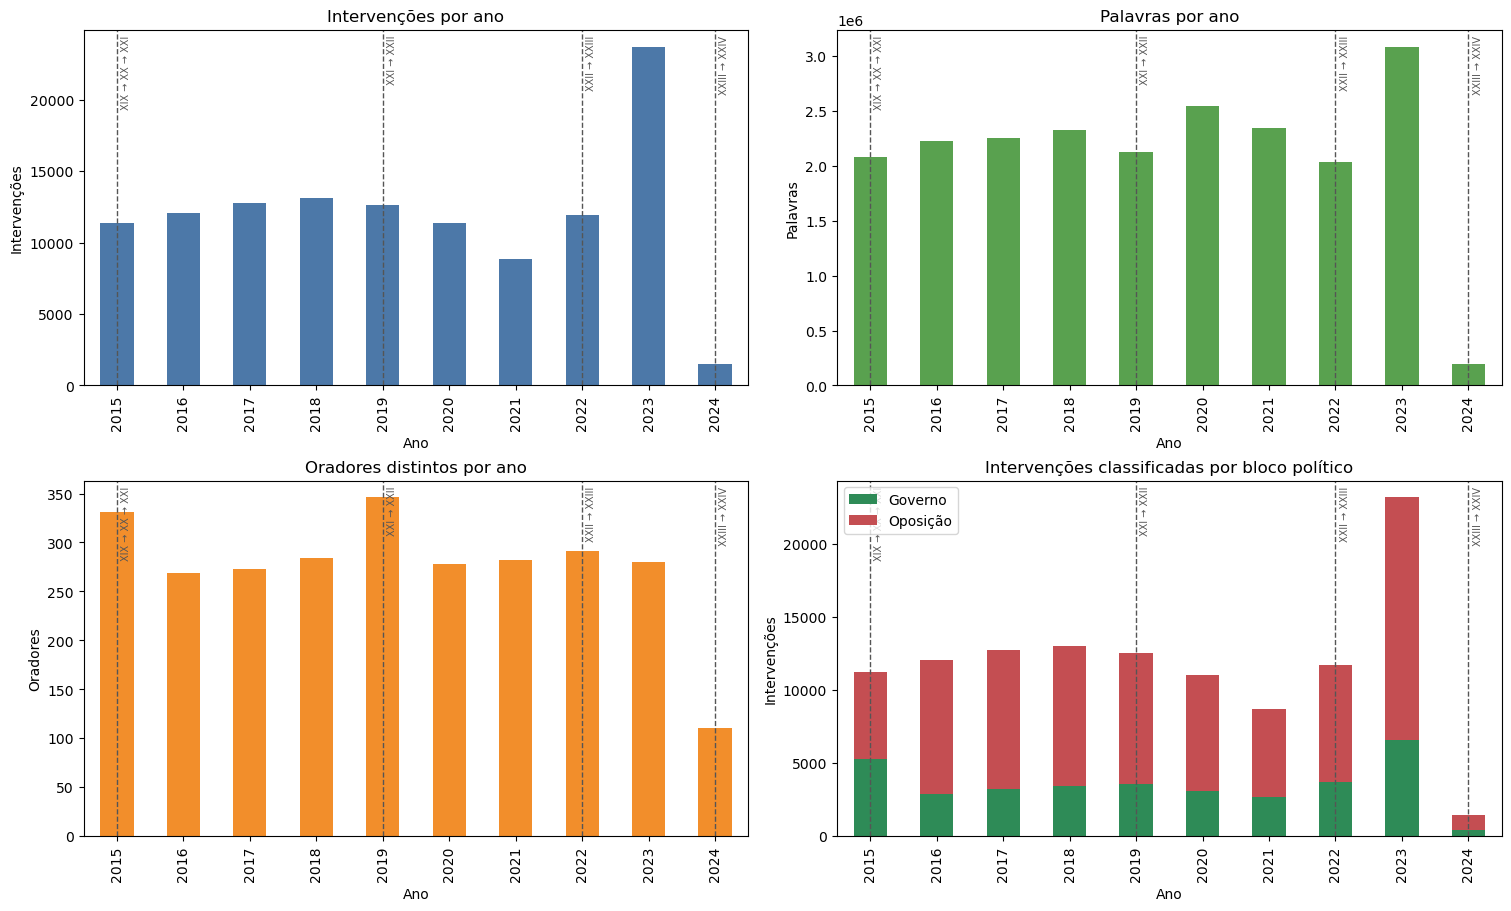

In [99]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)

resumo_anual["intervencoes"].plot.bar(ax=axes[0, 0], color="#4C78A8")
axes[0, 0].set(title="Intervenções por ano", xlabel="Ano", ylabel="Intervenções")

resumo_anual["palavras"].plot.bar(ax=axes[0, 1], color="#59A14F")
axes[0, 1].set(title="Palavras por ano", xlabel="Ano", ylabel="Palavras")

resumo_anual["oradores"].plot.bar(ax=axes[1, 0], color="#F28E2B")
axes[1, 0].set(title="Oradores distintos por ano", xlabel="Ano", ylabel="Oradores")

resumo_anual[["Governo", "Oposição"]].plot(
    kind="bar",
    stacked=True,
    ax=axes[1, 1],
    color=["#2E8B57", "#C44E52"],
)
axes[1, 1].set(
    title="Intervenções classificadas por bloco político",
    xlabel="Ano",
    ylabel="Intervenções",
)

for eixo in axes.flat:
    marcar_transicoes_governacao_anual(eixo)

plt.show()

### 7.1 Diagnóstico complementar de comparabilidade

As métricas seguintes não medem a qualidade dos tópicos. Medem se cada janela contém atividade e diversidade suficientes para que uma comparação temática posterior não seja explicada apenas por concentração em poucas pessoas, partidos ou tipos de interveniente.\n
\n
A tabela detalhada é útil para auditoria, mas o gráfico seguinte resume as quatro dimensões que distinguem as granularidades: volume, dias de atividade, diversidade mínima de pessoas oradoras e concentração máxima nas cinco pessoas oradoras mais ativas.

In [100]:
def numero_efetivo(serie):
    """Número efetivo de categorias: 1 / soma(p_i²)."""
    valores = serie.dropna().astype("string")
    proporcoes = valores.loc[valores.ne("")].value_counts(normalize=True)
    return 1 / proporcoes.pow(2).sum() if not proporcoes.empty else float("nan")


def indice_hhi(serie):
    """HHI: 1 indica concentração total; valores baixos indicam maior dispersão."""
    valores = serie.dropna().astype("string")
    proporcoes = valores.loc[valores.ne("")].value_counts(normalize=True)
    return proporcoes.pow(2).sum() if not proporcoes.empty else float("nan")


def quota_top_n(serie, n=5):
    valores = serie.dropna().astype("string")
    proporcoes = valores.loc[valores.ne("")].value_counts(normalize=True)
    return proporcoes.head(n).sum() if not proporcoes.empty else float("nan")


dados_comparabilidade = intervencoes_validas.copy()
dados_comparabilidade["tipo_orador"] = "Outro não deputado"
dados_comparabilidade.loc[dados_comparabilidade["Speaker_MP"].eq("MP"), "tipo_orador"] = "Deputado"
dados_comparabilidade.loc[dados_comparabilidade["ID"].isin(ids_membros_governo), "tipo_orador"] = "Membro do Governo"

marcos_politicos = {
    pd.Timestamp("2015-11-26"): "início do XXI Governo",
    pd.Timestamp("2019-10-06"): "eleições legislativas",
    pd.Timestamp("2020-03-18"): "primeiro estado de emergência COVID-19",
    pd.Timestamp("2022-01-30"): "eleições legislativas",
    pd.Timestamp("2022-03-30"): "início do XXIII Governo",
    pd.Timestamp("2024-03-10"): "eleições legislativas",
}

resumos_comparabilidade = {}
for nome, frequencia in janelas_temporais.items():
    resumo = (
        dados_comparabilidade.groupby(pd.Grouper(key="Date", freq=frequencia))
        .agg(
            intervencoes=("ID", "size"),
            palavras=("n_palavras", "sum"),
            mediana_palavras=("n_palavras", "median"),
            iqr_palavras=("n_palavras", lambda valores: valores.quantile(0.75) - valores.quantile(0.25)),
            dias_ativos=("Date", lambda datas: datas.dt.normalize().nunique()),
            oradores=("Speaker_ID", "nunique"),
            oradores_efetivos=("Speaker_ID", numero_efetivo),
            hhi_oradores=("Speaker_ID", indice_hhi),
            quota_top5_oradores=("Speaker_ID", quota_top_n),
            partidos=("Speaker_party", "nunique"),
            partidos_efetivos=("Speaker_party", numero_efetivo),
            hhi_partidos=("Speaker_party", indice_hhi),
            quota_top5_partidos=("Speaker_party", quota_top_n),
            inicio_observado=("Date", "min"),
            fim_observado=("Date", "max"),
        )
        .rename_axis("fim_periodo")
    )
    # Para comparabilidade, só se avaliam períodos observados com intervenções.
    resumo = resumo.loc[resumo["intervencoes"].gt(0)].copy()

    por_bloco = (
        dados_comparabilidade.loc[dados_comparabilidade["bloco_politico"].isin(blocos_esperados)]
        .groupby([pd.Grouper(key="Date", freq=frequencia), "bloco_politico"]).size()
        .unstack(fill_value=0).reindex(index=resumo.index, columns=blocos_esperados, fill_value=0)
    )
    total_classificado = por_bloco.sum(axis=1)
    resumo["proporcao_governo"] = por_bloco["Governo"].div(total_classificado.where(total_classificado.gt(0)))

    por_tipo = (
        dados_comparabilidade.groupby([pd.Grouper(key="Date", freq=frequencia), "tipo_orador"]).size()
        .unstack(fill_value=0).reindex(index=resumo.index, fill_value=0)
    )
    resumo["proporcao_membros_governo"] = por_tipo.get("Membro do Governo", pd.Series(0, index=resumo.index)).div(resumo["intervencoes"])
    resumo["proporcao_outros_nao_deputados"] = por_tipo.get("Outro não deputado", pd.Series(0, index=resumo.index)).div(resumo["intervencoes"])

    resumo["marcos_politicos"] = resumo.apply(
        lambda linha: "; ".join(
            rotulo for data, rotulo in marcos_politicos.items()
            if linha["inicio_observado"] <= data <= linha["fim_observado"]
        ) or pd.NA,
        axis=1,
    )
    resumos_comparabilidade[nome] = resumo

linhas_sintese_comparabilidade = []
for nome, resumo in resumos_comparabilidade.items():
    linhas_sintese_comparabilidade.append(
        {
            "janela": nome,
            "períodos_observados": len(resumo),
            "mediana_intervencoes": resumo["intervencoes"].median(),
            "mediana_dias_ativos": resumo["dias_ativos"].median(),
            "p10_oradores_efetivos": resumo["oradores_efetivos"].quantile(0.10),
            "mediana_oradores_efetivos": resumo["oradores_efetivos"].median(),
            "p90_quota_top5_oradores": resumo["quota_top5_oradores"].quantile(0.90),
            "p10_partidos_efetivos": resumo["partidos_efetivos"].quantile(0.10),
            "mediana_proporcao_governo": resumo["proporcao_governo"].median(),
        }
    )

sintese_comparabilidade = pd.DataFrame(linhas_sintese_comparabilidade).set_index("janela").round(3)
display(sintese_comparabilidade)


,períodos_observados,mediana_intervencoes,mediana_dias_ativos,p10_oradores_efetivos,mediana_oradores_efetivos,p90_quota_top5_oradores,p10_partidos_efetivos,mediana_proporcao_governo
janela,,,,,,,,
Semanal,359,327.0,3.0,12.051,30.010,0.505,4.176,0.283
Quinzenal,205,590.0,5.0,17.088,40.543,0.407,4.406,0.281
Mensal,102,1177.5,10.0,27.476,51.966,0.327,4.664,0.286



Semanal


,intervencoes,palavras,mediana_palavras,iqr_palavras,dias_ativos,oradores,oradores_efetivos,hhi_oradores,quota_top5_oradores,partidos,partidos_efetivos,hhi_partidos,quota_top5_partidos,inicio_observado,fim_observado,proporcao_governo,proporcao_membros_governo,proporcao_outros_nao_deputados,marcos_politicos
fim_periodo,,,,,,,,,,,,,,,,,,,
2015-01-11,444,74182,97.5,172.25,3,79,47.687,0.021,0.198,7,5.245,0.191,0.943,2015-01-07,2015-01-09,0.457,0.052,0.032,NaN
2015-01-18,278,53637,115.5,258.25,3,52,22.440,0.045,0.363,6,4.883,0.205,0.968,2015-01-14,2015-01-16,0.520,0.144,0.000,NaN
2015-01-25,350,53954,92.5,141.75,2,58,36.072,0.028,0.246,7,5.691,0.176,0.877,2015-01-21,2015-01-22,0.500,0.051,0.069,NaN
2015-02-01,374,64903,110.5,182.25,3,63,26.899,0.037,0.318,6,4.653,0.215,0.955,2015-01-28,2015-01-30,0.479,0.126,0.016,NaN
2015-02-08,342,58944,94.0,190.00,3,70,36.920,0.027,0.240,7,5.251,0.190,0.933,2015-02-04,2015-02-06,0.471,0.044,0.029,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-01-07,628,72623,65.0,106.00,3,73,35.364,0.028,0.264,9,4.947,0.202,0.922,2024-01-03,2024-01-05,0.276,0.046,0.073,NaN
2024-01-14,709,86556,61.0,116.00,3,71,30.475,0.033,0.291,10,5.428,0.184,0.885,2024-01-09,2024-01-11,0.285,0.062,0.035,NaN
2024-01-28,62,20777,240.5,443.50,1,17,8.393,0.119,0.613,8,4.072,0.246,0.871,2024-01-24,2024-01-24,0.435,0.258,0.016,NaN



Quinzenal


,intervencoes,palavras,mediana_palavras,iqr_palavras,dias_ativos,oradores,oradores_efetivos,hhi_oradores,quota_top5_oradores,partidos,partidos_efetivos,hhi_partidos,quota_top5_partidos,inicio_observado,fim_observado,proporcao_governo,proporcao_membros_governo,proporcao_outros_nao_deputados,marcos_politicos
fim_periodo,,,,,,,,,,,,,,,,,,,
2015-01-11,444,74182,97.5,172.25,3,79,47.687,0.021,0.198,7,5.245,0.191,0.943,2015-01-07,2015-01-09,0.457,0.052,0.032,NaN
2015-01-25,628,107591,98.0,180.00,5,85,47.243,0.021,0.209,7,5.392,0.185,0.917,2015-01-14,2015-01-22,0.509,0.092,0.038,NaN
2015-02-08,716,123847,103.0,186.00,6,101,48.964,0.020,0.205,7,4.978,0.201,0.944,2015-01-28,2015-02-06,0.475,0.087,0.022,NaN
2015-02-22,699,124010,109.0,186.50,6,97,40.511,0.025,0.249,7,5.234,0.191,0.888,2015-02-11,2015-02-20,0.582,0.187,0.077,NaN
2015-03-08,621,137553,125.0,279.00,6,96,42.968,0.023,0.214,8,5.585,0.179,0.922,2015-02-25,2015-03-06,0.437,0.019,0.016,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-31,653,78654,57.0,113.00,3,62,30.906,0.032,0.270,9,5.411,0.185,0.888,2023-12-19,2023-12-21,0.194,0.026,0.049,NaN
2024-01-14,1337,159179,63.0,110.00,6,109,38.664,0.026,0.259,10,5.284,0.189,0.885,2024-01-03,2024-01-11,0.281,0.055,0.053,NaN
2024-01-28,62,20777,240.5,443.50,1,17,8.393,0.119,0.613,8,4.072,0.246,0.871,2024-01-24,2024-01-24,0.435,0.258,0.016,NaN



Mensal


,intervencoes,palavras,mediana_palavras,iqr_palavras,dias_ativos,oradores,oradores_efetivos,hhi_oradores,quota_top5_oradores,partidos,partidos_efetivos,hhi_partidos,quota_top5_partidos,inicio_observado,fim_observado,proporcao_governo,proporcao_membros_governo,proporcao_outros_nao_deputados,marcos_politicos
fim_periodo,,,,,,,,,,,,,,,,,,,
2015-01-31,1446,246676,102.0,179.00,11,136,63.453,0.016,0.169,8,5.221,0.192,0.935,2015-01-07,2015-01-30,0.485,0.089,0.030,NaN
2015-02-28,1371,250420,105.0,198.50,12,150,62.955,0.016,0.176,8,5.468,0.183,0.904,2015-02-04,2015-02-27,0.514,0.112,0.047,NaN
2015-03-31,1336,252157,98.0,214.25,11,142,67.800,0.015,0.156,8,5.256,0.190,0.932,2015-03-04,2015-03-27,0.481,0.103,0.021,NaN
2015-04-30,1389,279437,114.0,223.00,14,151,57.535,0.017,0.197,7,4.749,0.211,0.952,2015-04-01,2015-04-30,0.534,0.181,0.010,NaN
2015-05-31,1499,262317,91.0,198.50,12,147,51.950,0.019,0.210,8,4.819,0.208,0.954,2015-05-06,2015-05-29,0.526,0.161,0.006,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-11-30,1330,151000,71.0,117.00,6,153,40.144,0.025,0.253,10,5.811,0.172,0.828,2023-11-23,2023-11-30,0.301,0.101,0.035,NaN
2023-12-31,1500,188242,61.0,120.00,8,114,42.414,0.024,0.229,9,5.978,0.167,0.857,2023-12-07,2023-12-21,0.206,0.074,0.039,NaN
2024-01-31,1399,179956,66.0,121.00,7,110,38.448,0.026,0.254,10,5.290,0.189,0.879,2024-01-03,2024-01-24,0.287,0.064,0.051,NaN


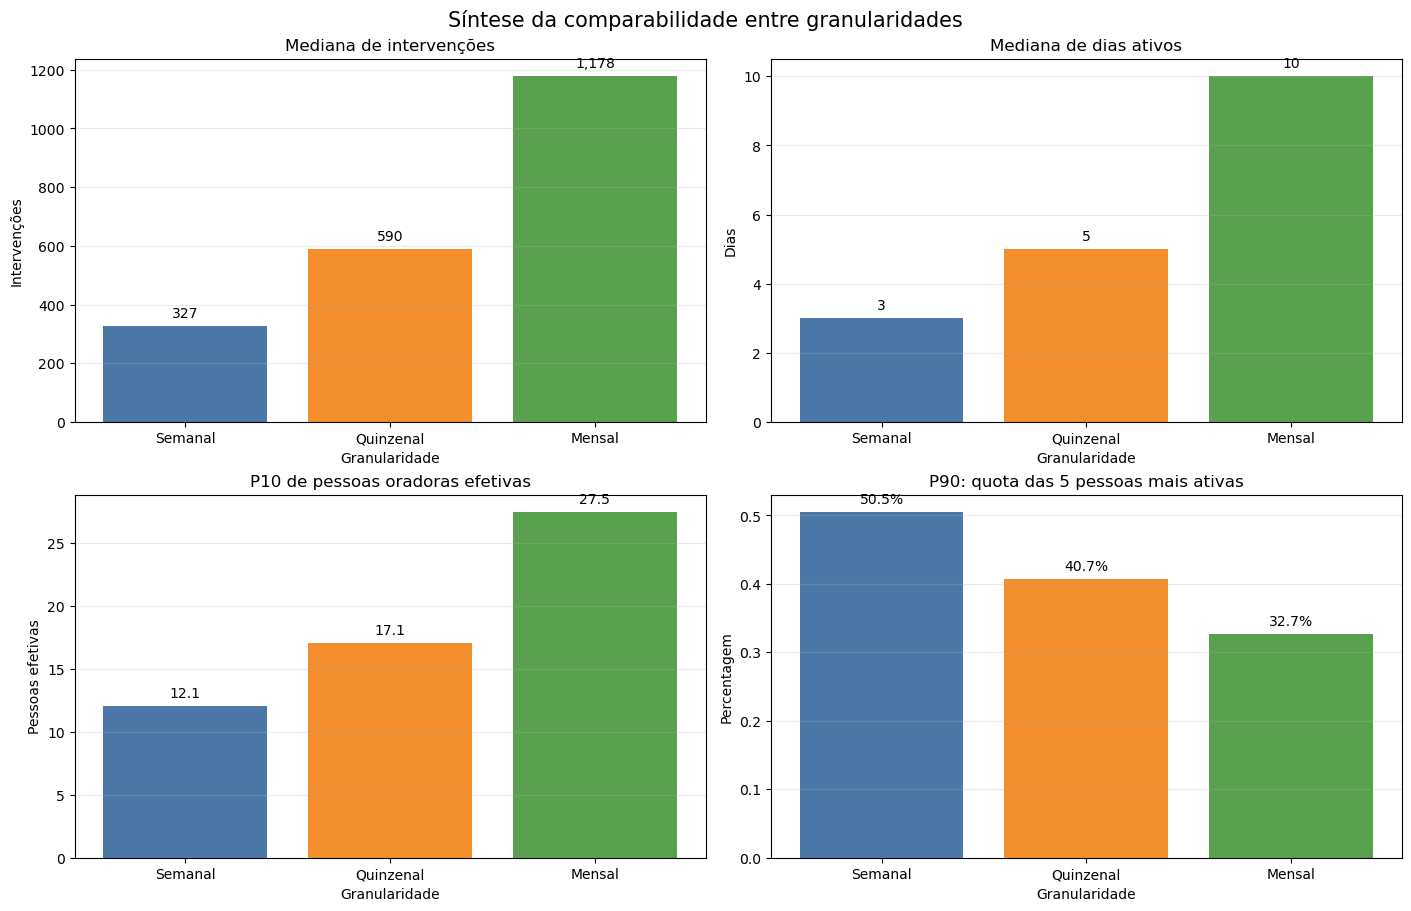

In [101]:
metricas_sintese = [
    ('mediana_intervencoes', 'Mediana de intervenções', 'Intervenções', 'inteiro'),
    ('mediana_dias_ativos', 'Mediana de dias ativos', 'Dias', 'inteiro'),
    ('p10_oradores_efetivos', 'P10 de pessoas oradoras efetivas', 'Pessoas efetivas', 'decimal'),
    ('p90_quota_top5_oradores', 'P90: quota das 5 pessoas mais ativas', 'Percentagem', 'percentagem'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
cores = ['#4C78A8', '#F28E2B', '#59A14F']

for eixo, (coluna, titulo, ylabel, formato) in zip(axes.flat, metricas_sintese):
    valores = sintese_comparabilidade[coluna]
    barras = eixo.bar(valores.index, valores, color=cores)
    eixo.set(title=titulo, xlabel='Granularidade', ylabel=ylabel)
    eixo.grid(axis='y', alpha=0.25)
    for barra, valor in zip(barras, valores):
        rotulo = f'{100 * valor:.1f}%' if formato == 'percentagem' else (
            f'{valor:.1f}' if formato == 'decimal' else f'{valor:,.0f}'
        )
        eixo.annotate(
            rotulo,
            (barra.get_x() + barra.get_width() / 2, barra.get_height()),
            ha='center', va='bottom', xytext=(0, 4), textcoords='offset points',
        )

fig.suptitle('Síntese da comparabilidade entre granularidades', fontsize=15)
plt.show()


### Conclusão do diagnóstico de comparabilidade

A granularidade mensal apresenta a base descritiva mais robusta entre as três alternativas avaliadas: a mediana sobe de 327 intervenções e 3 dias ativos na semana para 1 177,5 intervenções e 10 dias ativos no mês. Mesmo nos 10% de meses menos diversos, observam-se cerca de 27,5 pessoas oradoras efetivas, face a 12,1 na escala semanal. Em paralelo, nos períodos mais concentrados, a quota das cinco pessoas oradoras mais ativas desce de 50,5% na semana para 32,7% no mês.

A quinzena é uma solução intermédia: reduz parte da concentração semanal, mas mantém menor volume e diversidade do que o mês. A proporção mediana de intervenções do Governo é praticamente estável nas três granularidades (cerca de 28%), pelo que aumentar a janela não corrige nem cria esse desequilíbrio de composição; apenas torna a sua estimação menos volátil.

Estes resultados tornam a escala mensal uma candidata forte para experiências iniciais de modelação e alinhamento temporal. Não constituem, contudo, uma escolha final: será necessário confirmar que os tópicos mensais são coerentes e que as relações entre meses consecutivos são interpretáveis. Os períodos parciais de fevereiro e março de 2024 devem ser excluídos ou analisados separadamente em qualquer comparação de estabilidade.

-----